In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..") if os.path.basename(os.getcwd()) == "5" else os.getcwd())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

if 'google.colab' in str(get_ipython()):
    print("Google Colab 環境を検出しました。環境構築を開始します...")
    if not os.path.exists("study-mikanos"):
        !git clone https://github.com/miyayudai/study-mikanos.git
    %cd study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    !cmake -B build -S . > /dev/null && cmake --build build --target ch05_font_rendering_sim > /dev/null
    print("セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    print(f"ローカル実行環境です。(リポジトリルート: {repo_root})")


ローカル実行環境です。(リポジトリルート: /home/student/Documents/GitHub/study-mikanos)


# 5.1 文字を書いてみる (`Drawing Characters & References`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/5/5.1_Drawing_Characters_and_References.ipynb)
![Category](https://img.shields.io/badge/Category-Kernel_Graphics_&_Typography-blue.svg)
![Source](https://img.shields.io/badge/Source-osbook__day05a-orange.svg)
![Status](https://img.shields.io/badge/Status-Completed-brightgreen.svg)

---

### はじめに：文字表示のない OS の限界

前章（第4章）では、ベアメタル C++ における多態性（*Polymorphism*）と配置 new（*Placement new*）、仮想関数テーブル（*vtable*）の仕組みを解明し、さらに ELF64 セグメントローダによって C++ カーネルをメモリの正しい物理アドレスへロードして実行することに成功しました。

しかし、第4章終了時点の MikanOS には**画面に文字列やメッセージを表示する機能が一切存在しません**。
描画できるのは、単色の背景や矩形（四角形）などの幾何学模様だけです。

第1章では UEFI BIOS のファームウェアサービスである `ConOut->OutputString()` を利用してハローワールドを表示しましたが、第3章で `ExitBootServices()` を呼び出して以降、**ブートサービスは完全に破棄されており、ファームウェアの文字出力機能は二度と呼び出せません**。

ここから、**「自分たちの手だけでゼロから画面に文字（アルファベット・数字・記号）を描画する」** という OS 開発における大きな転換点が始まります。
本節では、文字描画の最も根源的な基盤である **8×16 ビットマップフォント（*Bitmap Font*）のビット展開アルゴリズム** と、C++ の重要言語機能である **参照（*Reference*）とポインタ（*Pointer*）の比較（コラム5.1）** を徹底的に解剖します。


## 1. なぜ OS にビットマップフォントが必要なのか？（動機と課題）

コンピュータの画面（ディスプレイ）は、数百万個の微細な光の点、すなわち **ピクセル（*Pixel*）の格子状の集合体** に過ぎません。
CPU やグラフィックスカードのハードウェアは、「文字 'A' を表示せよ」という抽象的な命令を直接解釈することはできず、VRAM（フレームバッファ）の特定番地に色データを書き込むことしかできません。

したがって、画面に文字を表示するためには、**「どの文字が、どのピクセルを点灯させ、どのピクセルを背景色のままにしておくべきか」** を定義した**形状データ（グリフ, *Glyph*）** をあらかじめ用意し、それを 1 ピクセルずつ VRAM に転送するアルゴリズムが必要です。

### アウトラインフォント vs ビットマップフォント
文字の形状を定義する方式には、現代の PC で主流の **アウトラインフォント（*Outline Font*, TrueType / OpenType）** と、黎明期から OS カーネルで広く使われる **ビットマップフォント（*Bitmap Font*）** があります。

| 方式 | 構造 | メリット | デメリット・OS起動時の課題 |
|---|---|---|---|
| **アウトラインフォント**<br>(TrueType / OpenType) | ベジェ曲線（数式）で文字の輪郭を保持 | 任意の拡大・縮小で輪郭が滑らか（ジャギーなし） | ラスタライズ（曲線のピクセル化）に膨大な浮動小数点演算と FreeType などの重厚なライブラリが必要。ベアメタル初期には利用不可。 |
| **ビットマップフォント**<br>(Bitmap Font) | 8×16 等の白黒ドット（ビット列）で文字形状を直接保持 | ビット演算（シフトと AND）だけで即座に VRAM へ転送可能。メモリ消費が極めて小さく、FPU/ライブラリ不要。 | 拡大するとギザギザ（ジャギー）が目立つ。フォントサイズごとに専用データが必要。 |

自作 OS の立ち上げフェーズにおいては、メモリ管理（ヒープ）や浮動小数点演算ユニット（FPU）の初期化すら完了していないため、**最もシンプルかつ高速に動作するビットマップフォント** を採用するのが必然の選択となります。


## 2. 8×16 ビットマップフォントのデータ構造とビット展開アルゴリズム

MikanOS では、標準的な PC/AT 互換機のテキストモード（VGA 80桁×25行）やコンソールで伝統的に広く採用されてきた **横 8 ピクセル × 縦 16 ピクセル（アスペクト比 1:2）** の半角フォント規格を採用しています。

### 1文字 16 バイトのメモリ効率
横 8 ピクセルは、ちょうど **1 バイト（8 ビット）** に収まります。
縦 16 ピクセルであるため、1 行あたり 1 バイト × 16 行 = **1 文字あたりわずか 16 バイト（128 ビット）** で文字の形状を完全に表現できます。

ASCII 文字コードの英数字・記号（0x20 〜 0x7E の約95文字）をすべて保持しても、`95 × 16 = 1520` バイト（約 1.5 KiB）に収まるため、キャッシュ効率も極めて優秀です。

### 文字 'A' のフォントデータ (`kFontA`)
`osbook_day05a` において、著者 uchan 氏が手書きで定義した文字 `'A'` のビットマップ配列が以下です：

```cpp
const uint8_t kFontA[16] = {
  0b00000000, // dy=0 :
  0b00011000, // dy=1 :    **
  0b00011000, // dy=2 :    **
  0b00011000, // dy=3 :    **
  0b00011000, // dy=4 :    **
  0b00100100, // dy=5 :   *  *
  0b00100100, // dy=6 :   *  *
  0b00100100, // dy=7 :   *  *
  0b00100100, // dy=8 :   *  *
  0b01111110, // dy=9 :  ******  (横棒: crossbar)
  0b01000010, // dy=10:  *    *
  0b01000010, // dy=11:  *    *
  0b01000010, // dy=12:  *    *
  0b11100111, // dy=13: ***  *** (裾広がり: legs)
  0b00000000, // dy=14:
  0b00000000, // dy=15:
};
```

### ビット展開アルゴリズムの数理
この配列から、座標 `(x, y)` に文字を描画する際、フォントの各ピクセル `(dx, dy)`（`0 <= dx < 8`, `0 <= dy < 16`）が点灯しているかどうかを判定する必要があります。

人間の視覚において、文字の左側は `dx = 0`、右側は `dx = 7` です。
一方、コンピュータの 1 バイト `uint8_t` において、左端のビットは **最上位ビット（MSB: Most Significant Bit, bit 7, `0x80`）** であり、右端のビットは **最下位ビット（LSB: Least Significant Bit, bit 0, `0x01`）** です。

したがって、左から右へ走査するインデックス `dx` に対応するビットを取り出すには、以下の **左シフト方式** が用いられます：

$$\text{is\_lit}(dx, dy) = \Big( (kFontA[dy] \ll dx) \ \& \ 0\text{x}80\text{u} \Big) \neq 0$$

- $dx = 0$ のとき: $kFontA[dy] \ll 0$。bit 7 (MSB) がそのまま $0\text{x}80$ でマスクされ、左端ピクセルの点灯を判定。
- $dx = 1$ のとき: $kFontA[dy] \ll 1$。bit 6 が最上位（bit 7 の位置）に繰り上がり、$0\text{x}80$ でマスク。
- $dx = 7$ のとき: $kFontA[dy] \ll 7$。bit 0 (LSB) が最上位に繰り上がり、$0\text{x}80$ でマスク。

また、数学的に完全に等価な **右シフト方式** も存在します：

$$\text{is\_lit\_alt}(dx, dy) = \Big( (kFontA[dy] \gg (7 - dx)) \ \& \ 1 \Big) \neq 0$$

左シフト方式はマスク値 $0\text{x}80$ が定数であり、x86-64 の `testb $0x80, %al` 命令等に直接マッピングできるため、カーネルコードで広く好まれます。


In [2]:
from common import GLYPH_A, FONT_A_RAW

print(f"グリフ文字: {GLYPH_A.char}")
print(f"サイズ: 幅 {GLYPH_A.width} ピクセル × 高さ {GLYPH_A.height} ピクセル")
print(f"点灯ピクセル総数: {GLYPH_A.count_lit_pixels()} 個 / 128 ビット")

# 各行のバイナリ表現とビット展開の等価性検証
print("\n[行ごとのビットデータ検証]")
for dy in range(GLYPH_A.height):
    byte_val = GLYPH_A.data[dy]
    left_shifts = [int(GLYPH_A.is_pixel_lit(dx, dy)) for dx in range(8)]
    right_shifts = [int(GLYPH_A.is_pixel_lit_right_shift(dx, dy)) for dx in range(8)]
    assert left_shifts == right_shifts, f"Row {dy} mismatch!"
    row_visual = "".join("■" if b else "・" for b in left_shifts)
    print(f"dy={dy:2d}: 0x{byte_val:02X} (0b{byte_val:08b}) -> {row_visual}")

print("\nASCII アート展開:")
print(GLYPH_A.to_ascii_art(lit_char="##", unlit_char=".."))


グリフ文字: A
サイズ: 幅 8 ピクセル × 高さ 16 ピクセル
点灯ピクセル総数: 34 個 / 128 ビット

[行ごとのビットデータ検証]
dy= 0: 0x00 (0b00000000) -> ・・・・・・・・
dy= 1: 0x18 (0b00011000) -> ・・・■■・・・
dy= 2: 0x18 (0b00011000) -> ・・・■■・・・
dy= 3: 0x18 (0b00011000) -> ・・・■■・・・
dy= 4: 0x18 (0b00011000) -> ・・・■■・・・
dy= 5: 0x24 (0b00100100) -> ・・■・・■・・
dy= 6: 0x24 (0b00100100) -> ・・■・・■・・
dy= 7: 0x24 (0b00100100) -> ・・■・・■・・
dy= 8: 0x24 (0b00100100) -> ・・■・・■・・
dy= 9: 0x7E (0b01111110) -> ・■■■■■■・
dy=10: 0x42 (0b01000010) -> ・■・・・・■・
dy=11: 0x42 (0b01000010) -> ・■・・・・■・
dy=12: 0x42 (0b01000010) -> ・■・・・・■・
dy=13: 0xE7 (0b11100111) -> ■■■・・■■■
dy=14: 0x00 (0b00000000) -> ・・・・・・・・
dy=15: 0x00 (0b00000000) -> ・・・・・・・・

ASCII アート展開:
................
......####......
......####......
......####......
......####......
....##....##....
....##....##....
....##....##....
....##....##....
..############..
..##........##..
..##........##..
..##........##..
######....######
................
................


## 3. 高解像度アーキテクチャ図版 (Figure 5.1) の徹底解剖

以下の図版（Figure 5.1）は、8×16 ビットマップフォント `'A'` の内部データ構造、ビット判定数理、および VRAM フレームバッファ上への描画結果を視覚化したものです。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:18384: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


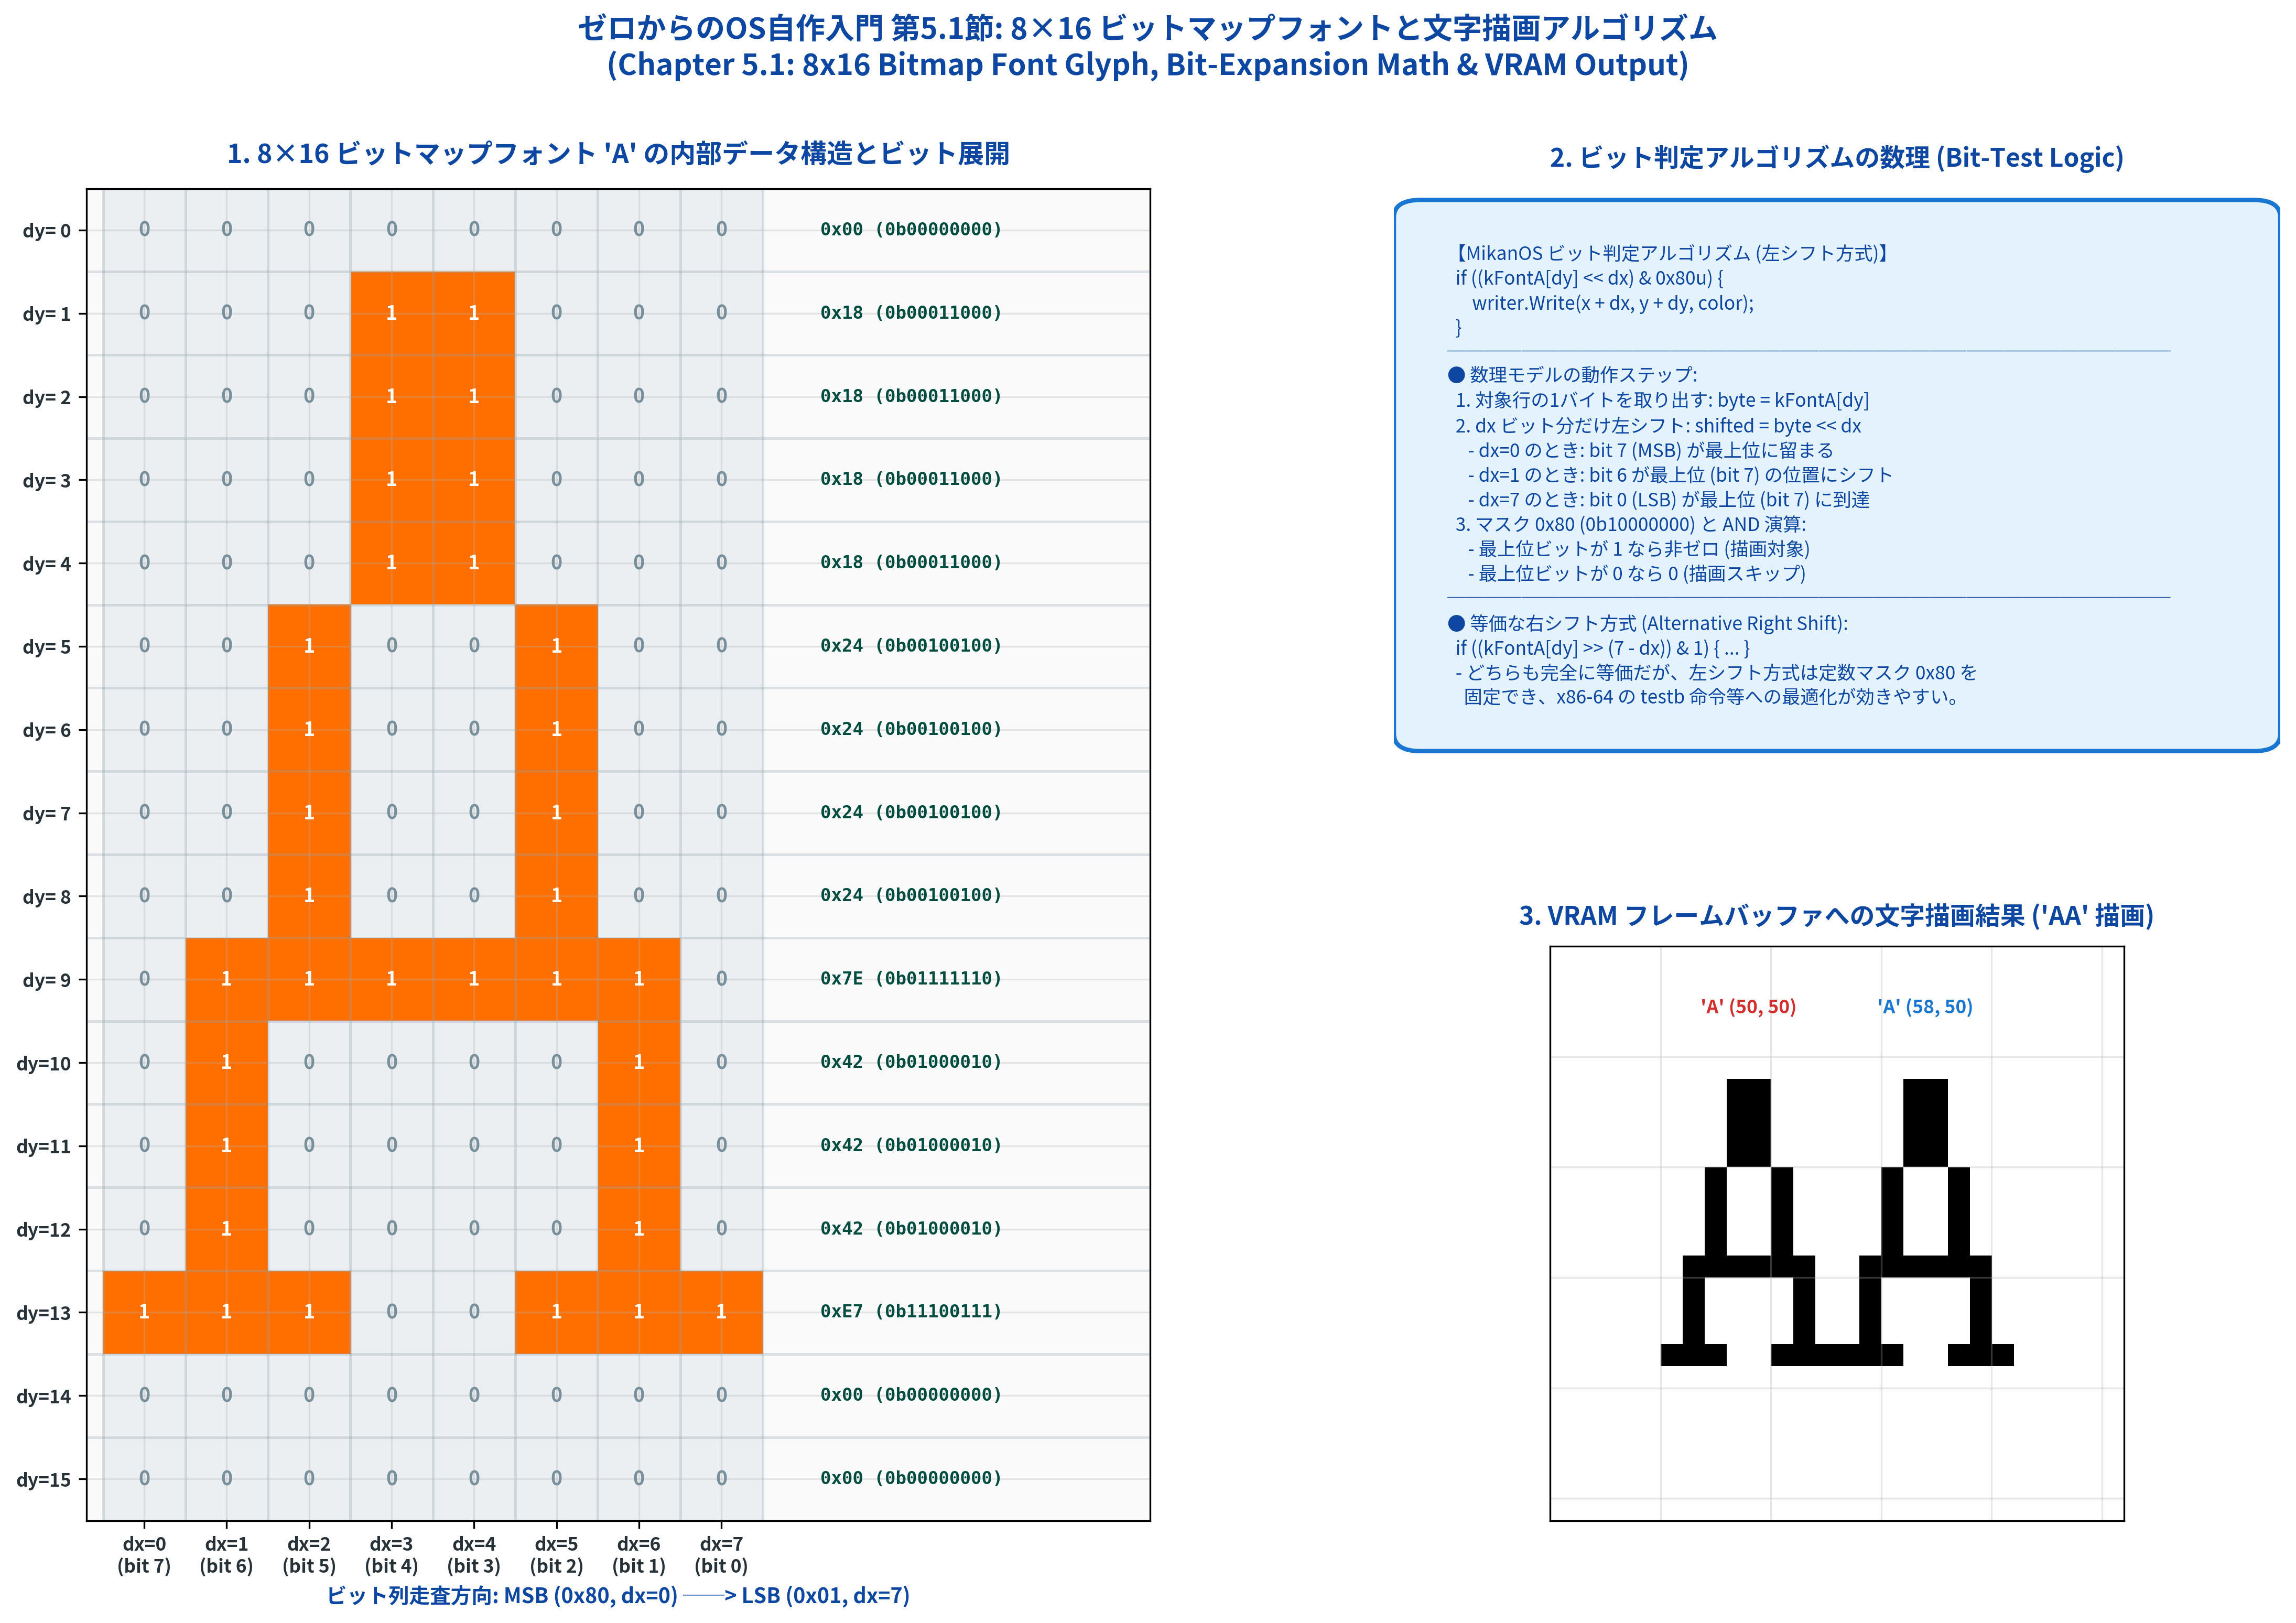

In [3]:
from common import plot_fig5_01_font_glyph_and_bit_expansion
from IPython.display import Image, display

fig5_01_path = plot_fig5_01_font_glyph_and_bit_expansion("5/result/fig5_01_font_glyph_and_bit_expansion.png")
display(Image(filename=str(fig5_01_path), width=900))


## 4. `WriteAscii` の実装と複数文字描画 (`"AA"`)

文字 `'A'` の形状データとビット判定アルゴリズムを組み合わせることで、指定した VRAM 座標に文字を描画する関数 `WriteAscii` が完成します。

```cpp
void WriteAscii(PixelWriter& writer, int x, int y, char c, const PixelColor& color) {
  if (c != 'A') {
    return;
  }
  for (int dy = 0; dy < 16; ++dy) {
    for (int dx = 0; dx < 8; ++dx) {
      if ((kFontA[dy] << dx) & 0x80u) {
        writer.Write(x + dx, y + dy, color);
      }
    }
  }
}
```

### 描画の幾何学：文字送り（*Character Advance*）
カーネルメイン関数 `KernelMain` では、文字 `'A'` を2つ並べて `"AA"` と描画しています：

```cpp
WriteAscii(*pixel_writer, 50, 50, 'A', {0, 0, 0});
WriteAscii(*pixel_writer, 58, 50, 'A', {0, 0, 0});
```

1文字目の開始 X 座標は `50` です。
フォントの幅は 8 ピクセルであるため、文字が占有する X 座標の範囲は `[50, 57]`（$50 + 0$ から $50 + 7$）となります。
したがって、2文字目をぴったり隣に隙間なく並べるためには、開始 X 座標を $50 + 8 = 58$ に設定します。
この文字幅に応じた次の文字描画位置へのオフセット加算を、タイポグラフィの世界で **文字送り（*Character Advance* または *Pitch*）** と呼びます。


In [4]:
from common import (
    FrameBufferConfigSim,
    PixelFormat,
    PixelColorSim,
    RGBResv8BitPerColorPixelWriterSim,
    write_ascii_sim,
    write_string_sim,
)

# 200x120 の仮想フレームバッファを作成
config = FrameBufferConfigSim(
    frame_buffer_base=0x8000_0000,
    pixels_per_scan_line=200,
    horizontal_resolution=200,
    vertical_resolution=120,
    pixel_format=PixelFormat.RGB_RESV_8BIT_PER_COLOR,
)
writer = RGBResv8BitPerColorPixelWriterSim(config)

# 1. 白背景クリア
for y in range(config.vertical_resolution):
    for x in range(config.horizontal_resolution):
        writer.write(x, y, PixelColorSim(255, 255, 255))

# 2. 緑矩形 (10, 10) - (100, 40)
for y in range(10, 40):
    for x in range(10, 100):
        writer.write(x, y, PixelColorSim(0, 200, 0))

# 3. 文字 'AA' を (50, 50) と (58, 50) に黒色で描画
drawn_1 = write_ascii_sim(writer, 50, 50, 'A', PixelColorSim(0, 0, 0))
drawn_2 = write_ascii_sim(writer, 58, 50, 'A', PixelColorSim(0, 0, 0))

print(f"1文字目 'A' 描画ピクセル数: {drawn_1}")
print(f"2文字目 'A' 描画ピクセル数: {drawn_2}")
print(f"合計点灯ピクセル数: {drawn_1 + drawn_2}")

# クロスバー (dy=9, y=59) のピクセル値検証
for dx in range(1, 7):
    # 1文字目
    off1 = writer.pixel_at(50 + dx, 59)
    assert writer.buffer[off1:off1+3] == bytearray([0, 0, 0])
    # 2文字目
    off2 = writer.pixel_at(58 + dx, 59)
    assert writer.buffer[off2:off2+3] == bytearray([0, 0, 0])

print("VRAM ピクセル検証: すべて正常に描画されました！")


1文字目 'A' 描画ピクセル数: 34
2文字目 'A' 描画ピクセル数: 34
合計点灯ピクセル数: 68
VRAM ピクセル検証: すべて正常に描画されました！


## 5. コラム 5.1「参照とポインタ」と C++ 型安全性の深層

`WriteAscii` の第1引数は、`PixelWriter* writer`（ポインタ）ではなく `PixelWriter& writer`（**参照: Reference**）として定義されています。

```cpp
void WriteAscii(PixelWriter& writer, int x, int y, char c, const PixelColor& color)
```

呼び出し側では、ポインタ `pixel_writer` を間接参照演算子 `*` でデリファレンスして渡しています：

```cpp
WriteAscii(*pixel_writer, 50, 50, 'A', {0, 0, 0});
```

### 参照（Reference）の本質と4大言語特性
C++ における参照とは、**「既存のオブジェクトに対する別の名前（エイリアス, Alias）」** です。
ポインタと比べて以下の決定的な違いがあります：

1. **NULL / nullptr の許容不可（非NULL保証）**:
   - ポインタは `nullptr` を保持できますが、参照は宣言時に必ず実在する有効なオブジェクトに束縛されなければなりません。
   - `PixelWriter& writer` と宣言されている関数は、内部で `if (writer == nullptr)` という無駄な防御的チェックを行う必要が一切なく、コードが堅牢かつ高速になります。
2. **再代入・再束縛の不可（不変エイリアス）**:
   - ポインタ変数 `ptr` は、`ptr = &another` によって指す先のアドレスを自由に変更できます。
   - 一方、参照 `ref` は一度初期化されると、後から別のオブジェクトを指すように変更することはできません。`ref = another` と書いた場合は、束縛先のオブジェクトに対する値のコピー代入になります。
3. **構文の簡潔さ（ドット記法）**:
   - ポインタ経由のメンバー呼び出しは `ptr->Write(...)` ですが、参照経由では通常の実体変数と全く同じ `ref.Write(...)` という自然なドット構文が使えます。
4. **自身のアドレスを持たない透過性**:
   - `&ptr` はポインタ変数自身がスタック上で保持されているアドレスを返しますが、`&ref` は束縛先オブジェクトのアドレスそのものを返します。

### 機械語レベルでの真実：ポインタ渡しと100%同一
「参照」は高級言語としての型安全性のための概念であり、**CPU やアセンブリのレベルでは、ポインタ渡しと全く同一の機械語が生成されます**。

System V AMD64 ABI において：
- `WriteAscii(PixelWriter& writer, ...)`
- `WriteAscii(PixelWriter* writer, ...)`

どちらの場合も、呼び出し元はオブジェクトのメモリアドレス（64ビット整数）を第1引数レジスタ **`RDI`** に格納して `call` 命令を発行します。
つまり、実行時オーバーヘッドはゼロ（*Zero-overhead abstraction*）でありながら、コンパイル時の安全性だけを最大限に高めることができるのが C++ 参照の真骨頂です。


## 6. 高解像度アーキテクチャ図版 (Figure 5.2) の徹底解剖

以下の図版（Figure 5.2）は、スタックフレームにおける参照とポインタのメモリモデル、System V AMD64 ABI のレジスタ渡し、および 6大特性比較対照表をまとめたものです。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:18501: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


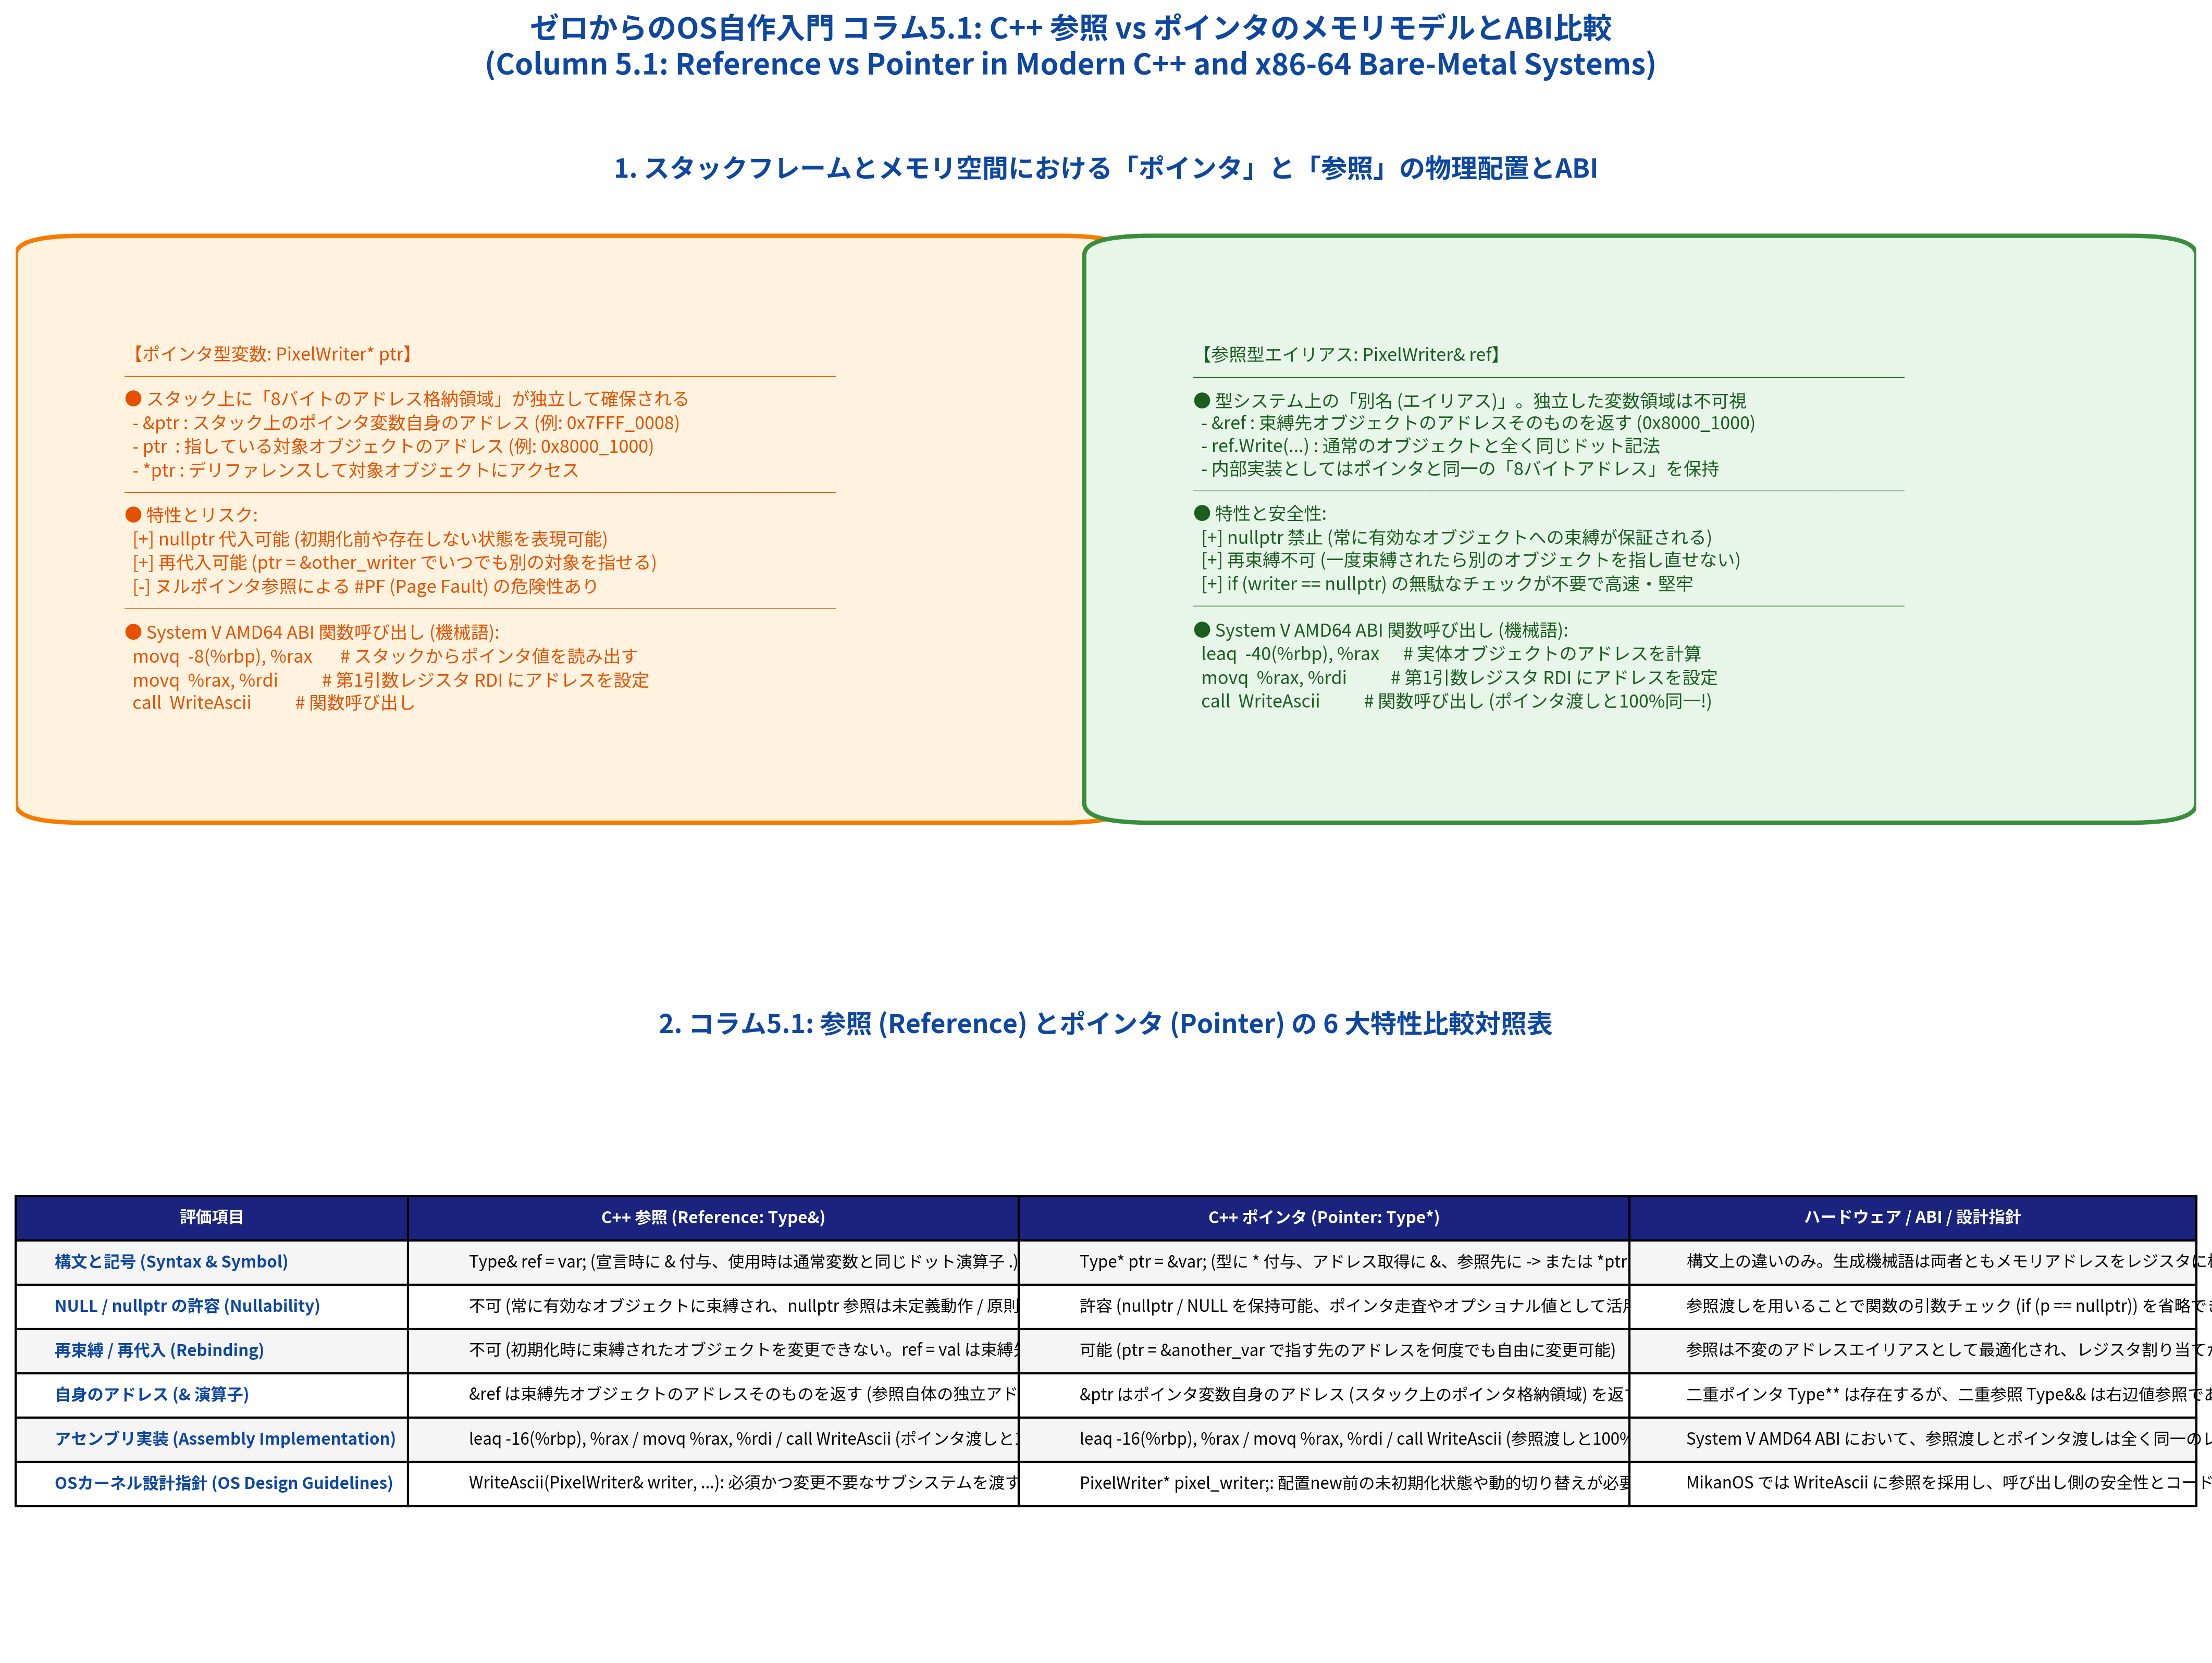

In [5]:
from common import plot_fig5_02_reference_vs_pointer_memory_model
from IPython.display import Image, display

fig5_02_path = plot_fig5_02_reference_vs_pointer_memory_model("5/result/fig5_02_reference_vs_pointer_memory_model.png")
display(Image(filename=str(fig5_02_path), width=900))


In [6]:
import pandas as pd
from common import get_reference_vs_pointer_comparisons

comparisons = get_reference_vs_pointer_comparisons()
df = pd.DataFrame([{
    "評価項目": c.feature,
    "C++ 参照 (Type&)": c.cpp_reference,
    "C++ ポインタ (Type*)": c.cpp_pointer,
    "ハードウェア / ABI": c.hardware_assembly_note
} for c in comparisons])

pd.set_option('display.max_colwidth', None)
display(df)


,評価項目,C++ 参照 (Type&),C++ ポインタ (Type*),ハードウェア / ABI
0,構文と記号 (Syntax & Symbol),Type& ref = var; (宣言時に & 付与、使用時は通常変数と同じドット演算子 .),Type* ptr = &var; (型に * 付与、アドレス取得に &、参照先に -> または *ptr),構文上の違いのみ。生成機械語は両者ともメモリアドレスをレジスタに格納して間接参照
1,NULL / nullptr の許容 (Nullability),不可 (常に有効なオブジェクトに束縛され、nullptr 参照は未定義動作 / 原則禁止),許容 (nullptr / NULL を保持可能、ポインタ走査やオプショナル値として活用可能),参照渡しを用いることで関数の引数チェック (if (p == nullptr)) を省略でき分岐予測と安全性が向上
2,再束縛 / 再代入 (Rebinding),不可 (初期化時に束縛されたオブジェクトを変更できない。ref = val は束縛先への値代入),可能 (ptr = &another_var で指す先のアドレスを何度でも自由に変更可能),参照は不変のアドレスエイリアスとして最適化され、レジスタ割り当てが容易
3,自身のアドレス (& 演算子),&ref は束縛先オブジェクトのアドレスそのものを返す (参照自体の独立アドレスは不可視),&ptr はポインタ変数自身のアドレス (スタック上のポインタ格納領域) を返す,二重ポインタ Type** は存在するが、二重参照 Type&& は右辺値参照であり意味が全く異なる
4,アセンブリ実装 (Assembly Implementation),"leaq -16(%rbp), %rax / movq %rax, %rdi / call WriteAscii (ポインタ渡しと100%同一)","leaq -16(%rbp), %rax / movq %rax, %rdi / call WriteAscii (参照渡しと100%同一)",System V AMD64 ABI において、参照渡しとポインタ渡しは全く同一のレジスタ渡し規約に従う
5,OSカーネル設計指針 (OS Design Guidelines),"WriteAscii(PixelWriter& writer, ...): 必須かつ変更不要なサブシステムを渡す際に推奨",PixelWriter* pixel_writer;: 配置new前の未初期化状態や動的切り替えが必要な場合に必須,MikanOS では WriteAscii に参照を採用し、呼び出し側の安全性とコード簡潔性を両立


## 7. C++20 スタンドアロン検証コード (`src/ch05/font_rendering_sim.cpp`) の実行

ホスト Linux 環境上で、MikanOS の文字描画ロジックと C++20 言語機能（参照 vs ポインタ、ビットシフト等価性、VRAM 出力、ベンチマーク）を検証するスタンドアロンプログラムを実行します。


In [7]:
import subprocess

# 1. CMake によるビルド
build_res = subprocess.run(
    ["cmake", "--build", "build", "--target", "ch05_font_rendering_sim"],
    cwd=repo_root, capture_output=True, text=True
)
print("[CMake Build Output]")
print(build_res.stdout)
assert build_res.returncode == 0, f"Build failed: {build_res.stderr}"

# 2. C++20 バイナリの実行
run_res = subprocess.run(
    ["./build/bin/ch05_font_rendering_sim"],
    cwd=repo_root, capture_output=True, text=True
)
print("[Executable Output]")
print(run_res.stdout)
assert run_res.returncode == 0, f"Execution failed: {run_res.stderr}"


[CMake Build Output]
[100%] Built target ch05_font_rendering_sim

[Executable Output]
 MikanOS Chapter 5.1: Drawing Characters & References (day05a)   
Testing Font 'A' Bitmap Structure & Bit-Test Mathematics... PASSED (34 lit pixels, bit-test equivalence verified)
Testing WriteAscii Character Rendering (RGB & BGR)... PASSED
Testing Column 5.1: C++ Reference vs Pointer Principles... PASSED (Address identity & ABI equivalence confirmed)
Testing Day05a Full VRAM Scene Simulation (White bg + Green rect + 'AA')... PASSED
Benchmarking 100,000 WriteAscii Calls... PASSED (32.31 ms for 100k glyphs, 3095327.42 glyphs/sec)
 All Section 5.1 C++20 Verification Tests Passed Successfully!   



## 8. 本節のまとめと次節（5.2節 分割コンパイル）への展望

### 本節で獲得した中核知識
1. **ビットマップフォントの原理と規格**:
   - 画面はピクセルグリッドであり、文字を表現するには白黒ドットの形状（グリフ）が必要。
   - 8×16 の規格により、1文字あたり 16 バイト（128 ビット）という圧倒的なコンパクトさで文字を保持可能。
2. **ビット展開アルゴリズムの数理**:
   - 左シフト `(kFontA[dy] << dx) & 0x80u` によって、左端（MSB, $dx=0$）から右端（LSB, $dx=7$）へのピクセル点灯判定を高速実行。
   - 右シフト `(kFontA[dy] >> (7 - dx)) & 1` との数学的等価性を証明。
3. **文字送り（Character Advance）**:
   - 2文字目以降を描画する際、開始 X 座標を文字幅分（$+8$ ピクセル）進めることで隙間なく文字列を整列。
4. **コラム5.1「参照とポインタ」の真実**:
   - 参照は型システム上の安全なエイリアス（NULL禁止・再束縛不可・ドット記法）。
   - 機械語レベルでは System V AMD64 ABI の第1引数レジスタ `RDI` にアドレスを渡すポインタ渡しと100%同一であり、実行時オーバーヘッドはゼロ。

---

### 次節への展望：5.2節「分割コンパイル (`osbook_day05b`)」
本節では `main.cpp` の中に文字 `'A'` のフォントデータを直書きしました。
しかし、このままではアルファベット大文字・小文字、数字、記号などのすべての文字データを定義すると `main.cpp` が数百行に肥大化してしまいます。
また、文字描画関数 `WriteAscii` やグラフィックス描画関数が1つのファイルに混在すると、保守性やビルド速度が著しく低下します。

次節 **5.2節「分割コンパイル (`osbook_day05b`)」** では、C++ の **ヘッダファイル（宣言）とソースファイル（定義）の分離**、インクルードガード（`#pragma once`）、およびリンカによるシンボル解決のメカニズムを学び、プロフェッショナルな OS アーキテクチャへのモジュール化に挑みます！
